# Lecture 6 — Class Exercise
## Choropleth Maps

> **Push to:** `week06/lecture06_exercise.ipynb`

**Rules:**
1. Use `px.choropleth` or `px.choropleth_map` — choose deliberately and state your reason
2. Right colour scale for your data (sequential vs diverging) — state which and why
3. Insight title names a geographic finding — not just a topic
4. `featureidkey` must be correctly matched to your GeoJSON

---


In [8]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import json


## Task 1 — World choropleth: life expectancy diverging scale

**What to build:** A world choropleth showing **life expectancy relative to the global average** using a diverging colour scale.

**Requirements:**
- Use the Gapminder dataset for 2007: `px.data.gapminder()`
- Compute each country's deviation from the global mean life expectancy
- Diverging scale centred at zero (= world average)
- `hover_data` showing country name, raw life expectancy, and deviation
- Insight title naming which region is furthest below average

> 💡 `gm_2007['lifeExp'].mean()` gives you the global average to subtract from


Global average life expectancy: 67.01


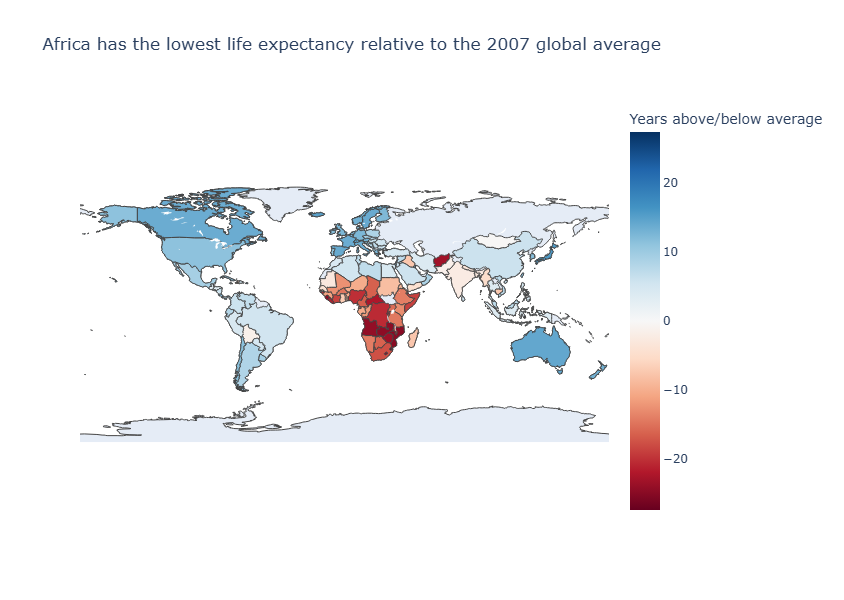

In [9]:
# Task 1
# YOUR CODE HERE

# Task 1 - World Life Expectancy Choropleth

# Load Gapminder dataset
gm = px.data.gapminder()

# Filter data for 2007
gm_2007 = gm[gm['year'] == 2007].copy()

# Calculate global average life expectancy
global_avg = gm_2007['lifeExp'].mean()

print("Global average life expectancy:", round(global_avg, 2))

# Calculate deviation from global average
gm_2007['deviation'] = gm_2007['lifeExp'] - global_avg

# Create choropleth map
fig = px.choropleth(
    gm_2007,
    locations='iso_alpha',
    locationmode='ISO-3',
    color='deviation',

    # Diverging colour scale
    color_continuous_scale='RdBu',
    color_continuous_midpoint=0,

    hover_name='country',
    hover_data={
        'lifeExp': ':.2f',
        'deviation': ':+.2f',
        'iso_alpha': False
    },

    labels={
        'lifeExp': 'Life Expectancy (years)',
        'deviation': 'Difference from Global Average (years)'
    },

    title='Africa has the lowest life expectancy relative to the 2007 global average',
    height=600
)

fig.update_layout(
    geo=dict(showframe=False),
    coloraxis_colorbar=dict(
        title='Years above/below average'
    )
)

fig.show()


## Task 2 — Find your own GeoJSON

**What to build:** A choropleth using a GeoJSON file you find yourself online.

**Requirements:**
- Find a free GeoJSON file for any geography that interests you (country, region, city)
- Create or find a matching dataset with at least one numeric variable per region
- Build either a `px.choropleth` or `px.choropleth_mapbox` — state your choice and reason in the markdown cell below
- Correctly identify and set `featureidkey` by inspecting the GeoJSON properties
- Choose sequential or diverging scale — state your reason in the markdown cell below
- Insight title naming a geographic finding

**Where to find GeoJSON files:**
- [geojson.xyz](https://geojson.xyz/) — countries, cities, natural features
- [naturalearthdata.com](https://www.naturalearthdata.com/) — global admin boundaries
- [github.com/datasets/geo-countries](https://github.com/datasets/geo-countries) — country polygons
- Search: `[country name] [admin level] GeoJSON github` — most countries have free boundary files on GitHub

> 💡 Before plotting, always inspect your GeoJSON properties first:
> ```python
> print(my_geojson['features'][0]['properties'])
> ```
> The property name that matches your dataframe's location column is what goes in `featureidkey='properties.???'`


### Task 2 — Design decisions

**GeoJSON source:** *(URL or description)*

**Chart type chosen** (`px.choropleth` or `px.choropleth_mapbox`) **and reason:**

*Your answer here*

**Colour scale chosen** (sequential or diverging) **and reason:**

*Your answer here*


In [14]:
from pathlib import Path
import json

print("cwd =", Path.cwd())

candidates = [
    Path("data/africa.json"),
    Path("../data/africa.json"),
    Path.cwd() / "data" / "africa.json",
    Path.cwd().parent / "data" / "africa.json",
]

for p in candidates:
    print(p, "exists =", p.exists())

geojson_path = next((p for p in candidates if p.exists()), candidates[0])
print("using:", geojson_path)

cwd = C:\Users\pavan\data-viz-class-material-w2026pavanpitta\week06
data\africa.json exists = False
..\data\africa.json exists = True
C:\Users\pavan\data-viz-class-material-w2026pavanpitta\week06\data\africa.json exists = False
C:\Users\pavan\data-viz-class-material-w2026pavanpitta\data\africa.json exists = True
using: ..\data\africa.json


GeoJSON properties: ['featurecla', 'scalerank', 'labelrank', 'sovereignt', 'sov_a3', 'adm0_dif', 'level', 'type', 'tlc', 'admin', 'adm0_a3', 'geou_dif', 'geounit', 'gu_a3', 'su_dif', 'subunit', 'su_a3', 'brk_diff', 'name', 'name_long', 'brk_a3', 'brk_name', 'brk_group', 'abbrev', 'postal', 'formal_en', 'formal_fr', 'name_ciawf', 'note_adm0', 'note_brk', 'name_sort', 'name_alt', 'mapcolor7', 'mapcolor8', 'mapcolor9', 'mapcolor13', 'pop_est', 'pop_rank', 'pop_year', 'gdp_md', 'gdp_year', 'economy', 'income_grp', 'fips_10', 'iso_a2', 'iso_a2_eh', 'iso_a3', 'iso_a3_eh', 'iso_n3', 'iso_n3_eh', 'un_a3', 'wb_a2', 'wb_a3', 'woe_id', 'woe_id_eh', 'woe_note', 'adm0_iso', 'adm0_diff', 'adm0_tlc', 'adm0_a3_us', 'adm0_a3_fr', 'adm0_a3_ru', 'adm0_a3_es', 'adm0_a3_cn', 'adm0_a3_tw', 'adm0_a3_in', 'adm0_a3_np', 'adm0_a3_pk', 'adm0_a3_de', 'adm0_a3_gb', 'adm0_a3_br', 'adm0_a3_il', 'adm0_a3_ps', 'adm0_a3_sa', 'adm0_a3_eg', 'adm0_a3_ma', 'adm0_a3_pt', 'adm0_a3_ar', 'adm0_a3_jp', 'adm0_a3_ko', 'adm0_a3_vn

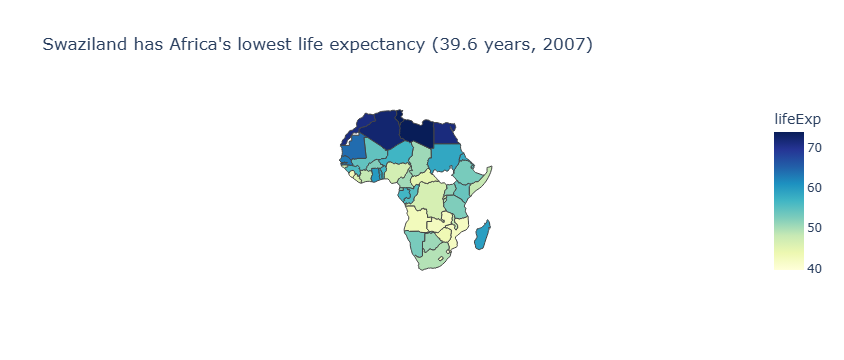

In [16]:
# Task 2
# Load the course-provided Natural Earth GeoJSON for African countries.
from pathlib import Path

geojson_candidates = [
    Path("data/africa.json"),
    Path("../data/africa.json"),
    Path.cwd() / "data" / "africa.json",
    Path.cwd().parent / "data" / "africa.json",
]
geojson_path = next((path for path in geojson_candidates if path.exists()), geojson_candidates[0])

with open(geojson_path, "r", encoding="utf-8") as file:
    my_geojson = json.load(file)

# Inspect the GeoJSON properties; the matching country field is "admin".
print("GeoJSON properties:", list(my_geojson["features"][0]["properties"].keys()))
featureidkey = "properties.admin"

# Use Gapminder's 2007 life expectancy values for African countries.
africa_life = px.data.gapminder().query(
    "year == 2007 and continent == 'Africa'"
).copy()

# Align country names that differ between Gapminder and Natural Earth.
country_aliases = {
    "Congo, Dem. Rep.": "Democratic Republic of the Congo",
    "Congo, Rep.": "Republic of the Congo",
    "Cote d'Ivoire": "Ivory Coast",
    "Swaziland": "eSwatini",
    "Tanzania": "United Republic of Tanzania",
}
africa_life["geo_name"] = africa_life["country"].replace(country_aliases)
geo_names = {
    feature["properties"]["admin"] for feature in my_geojson["features"]
}
africa_life = africa_life[africa_life["geo_name"].isin(geo_names)].copy()

lowest_country = africa_life.loc[
    africa_life["lifeExp"].idxmin(), "country"
]
lowest_life_expectancy = africa_life["lifeExp"].min()
print(f"Countries matched to GeoJSON: {len(africa_life)}")
print(
    f"Lowest life expectancy: {lowest_country} "
    f"({lowest_life_expectancy:.1f} years)"
)

fig = px.choropleth(
    africa_life,
    geojson=my_geojson,
    locations="geo_name",
    featureidkey=featureidkey,
    color="lifeExp",
    hover_name="country",
    hover_data={"lifeExp": ":.1f", "gdpPercap": ":,.0f", "geo_name": False},
    color_continuous_scale="YlGnBu",
    title=f"{lowest_country} has Africa's lowest life expectancy ({lowest_life_expectancy:.1f} years, 2007)"
)
fig.update_geos(fitbounds="locations", visible=False)
fig.show()